<a href="https://colab.research.google.com/github/ryanaxiom/Applied-ML/blob/main/code/Day22_Trees01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Student Instructions**: Before you begin, click **File > Save a copy in Drive** so you do not lose your work!

In [1]:
url = ("https://raw.githubusercontent.com/ryanaxiom/Applied-ML/main/data/carnegie_data.csv")

import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, cross_val_score
carnegie_raw = pd.read_csv(url, encoding="cp1252")
carnegie = carnegie_raw.copy()
carnegie["research"] = carnegie["serd"] + carnegie["nonserd"]
d = carnegie[carnegie["research"].notna()].copy()
d["med_yn"] = (d["medical"] == 1).astype(int)
y = d["research"]
kf = KFold(n_splits=5, shuffle=True, random_state=309)
cols = ["fallenr20", "grtenr20", "docrsdeg", "totdeg", "rooms"]
ctl = carnegie["control"].map({1: "public", 2: "nonprofit",
                               3: "for-profit"})
print(carnegie.shape, d.shape)

(3939, 102) (302, 103)


In [2]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_transformer
print(pd.crosstab(carnegie["sector"], ctl))
logged = make_pipeline(FunctionTransformer(np.log1p),
                       StandardScaler())
prep = make_column_transformer((logged, cols),
                               (OneHotEncoder(), ["sector"]))
leaky = make_pipeline(prep, LogisticRegression())
acc = cross_val_score(leaky, carnegie[cols + ["sector"]], ctl,
                      cv=kf, scoring="accuracy")
print(round(acc.mean(), 4))

control  for-profit  nonprofit  public
sector                                
1                 0          0     785
2                 0       1591       0
3               316          0       0
4                 0          0     843
5                 0         75       0
6               329          0       0
1.0


In [3]:
nh = pd.read_csv(url.replace("carnegie_data", "nhanes_adults"))
yd = (nh["Diabetes"] == "Yes").astype(int)
nh["male"] = (nh["Sex"] == "male").astype(int)
exam = ["Age", "BMI", "BPSysAve", "BPDiaAve", "Pulse",
        "TotChol", "DirectChol", "male"]
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.impute import SimpleImputer
tree = make_pipeline(SimpleImputer(strategy="median"),
                     DecisionTreeClassifier(max_depth=2,
                                            random_state=309))
tree.fit(nh[exam], yd)
print(export_text(tree[-1], feature_names=exam, show_weights=True))

|--- Age <= 49.50
|   |--- Age <= 40.50
|   |   |--- weights: [4156.00, 113.00] class: 0
|   |--- Age >  40.50
|   |   |--- weights: [1588.00, 184.00] class: 0
|--- Age >  49.50
|   |--- TotChol <= 4.33
|   |   |--- weights: [758.00, 543.00] class: 0
|   |--- TotChol >  4.33
|   |   |--- weights: [3599.00, 828.00] class: 0



0.0265
0.1038
0.4174
0.187


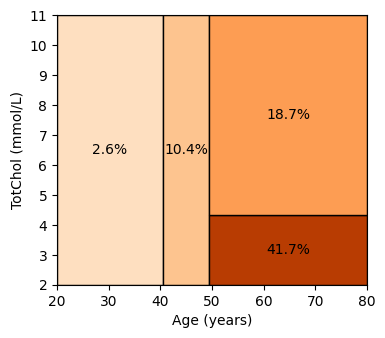

In [4]:
for num, den in [(113, 4269), (184, 1772), (543, 1301), (828, 4427)]:
    print(round(num / den, 4))
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(4, 3.5))
boxes = [(20, 2, 20.5, 9, 113 / 4269), (40.5, 2, 9, 9, 184 / 1772),
         (49.5, 2, 30.5, 2.33, 543 / 1301), (49.5, 4.33, 30.5, 6.67, 828 / 4427)]
for x0, y0, w, h, rate in boxes:
    ax.add_patch(Rectangle((x0, y0), w, h, facecolor=plt.cm.Oranges(0.12 + rate * 1.7),
                           edgecolor="black"))
    ax.text(x0 + w / 2, y0 + h / 2, f"{rate:.1%}", ha="center", va="center")
ax.set_xlim(20, 80); ax.set_ylim(2, 11)
ax.set_xlabel("Age (years)"); ax.set_ylabel("TotChol (mmol/L)"); plt.show()

In [5]:
filled = nh[exam].fillna(nh[exam].median())
def gini(y):                 # 1 - (share yes)^2 - (share no)^2
    return 1 - y.mean()**2 - (1 - y.mean())**2
print("root", round(gini(yd), 4))
for col in exam:
    x = np.sort(filled[col].unique())
    scores = {}
    for cut in (x[:-1] + x[1:]) / 2:            # every midpoint
        left = filled[col] <= cut
        scores[cut] = (left.mean() * gini(yd[left])
                       + (1 - left.mean()) * gini(yd[~left]))
    cut = min(scores, key=scores.get)            # the best cut
    print(col, float(cut), round(float(scores[cut]), 4))

root 0.2433
Age 49.5 0.2252
BMI 29.835 0.2362
BPSysAve 125.5 0.2372
BPDiaAve 51.5 0.2417
Pulse 87.0 0.2428
TotChol 4.205 0.24
DirectChol 1.205 0.2411
male 0.5 0.2432


In [6]:
print(exam[tree[-1].tree_.feature[0]], tree[-1].tree_.threshold[0],
      round(float(tree[-1].tree_.impurity[0]), 4))

Age 49.5 0.2433


In [7]:
for depth in [1, 2, 3, 4, 6, None]:
    tree = make_pipeline(SimpleImputer(strategy="median"),
                         DecisionTreeClassifier(max_depth=depth,
                                                random_state=309))
    auc = cross_val_score(tree, nh[exam], yd, cv=kf,
                          scoring="roc_auc")
    ll = cross_val_score(tree, nh[exam], yd, cv=kf,
                         scoring="neg_log_loss")
    tree.fit(nh[exam], yd)
    print(depth, tree[-1].get_n_leaves(), round(auc.mean(), 4),
          round(-ll.mean(), 4))

1 2 0.6912 0.3701
2 4 0.7454 0.3546
3 8 0.7704 0.3463
4 16 0.7802 0.3502
6 61 0.7796 0.4574
None 1572 0.6034 7.2153


In [8]:
for alpha in [0, 0.0003, 0.001, 0.003, 0.01]:
    tree = make_pipeline(SimpleImputer(strategy="median"),
                         DecisionTreeClassifier(ccp_alpha=alpha,
                                                random_state=309))
    ll = cross_val_score(tree, nh[exam], yd, cv=kf,
                         scoring="neg_log_loss")
    tree.fit(nh[exam], yd)
    print(alpha, tree[-1].get_n_leaves(), tree[-1].get_depth(),
          round(-ll.mean(), 4))

0 1572 41 7.2153
0.0003 39 12 0.5888
0.001 8 4 0.3485
0.003 4 3 0.3563
0.01 2 1 0.3701
